In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
file_path = "NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(2))

FileNotFoundError: [Errno 2] No such file or directory: 'NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv'

In [4]:
import pandas as pd

file_path = "C:\Users\POOJA\Downloads\NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(2))

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (3016716280.py, line 3)

In [5]:
import pandas as pd

file_path = r"C:\Users\POOJA\Downloads\NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(2))

Dataset loaded successfully!
Dataset shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       7787 non-null   str  
 1   type          7787 non-null   str  
 2   title         7787 non-null   str  
 3   director      5398 non-null   str  
 4   cast          7069 non-null   str  
 5   country       7280 non-null   str  
 6   date_added    7777 non-null   str  
 7   release_year  7787 non-null   int64
 8   rating        7780 non-null   str  
 9   duration      7787 non-null   str  
 10  listed_in     7787 non-null   str  
 11  description   7787 non-null   str  
dtypes: int64(1), str(11)
memory usage: 730.2 KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,3%,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

Total missing values: 3631
Duplicate rows: 0


In [8]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing text values
text_columns = [
    "type", "title", "director", "cast",
    "country", "rating", "duration",
    "listed_in", "description"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown").astype(str)

# Convert release year to numeric
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"], errors="coerce"
)

print("Data cleaning completed!")
print("Dataset shape:", df.shape)

print("\nMissing values after cleaning:")
display(df.isnull().sum())

Data cleaning completed!
Dataset shape: (7787, 12)

Missing values after cleaning:


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

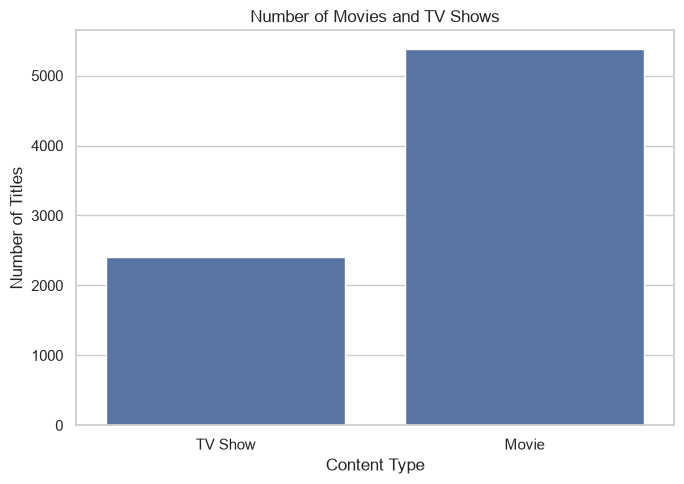

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="type")

plt.title("Number of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

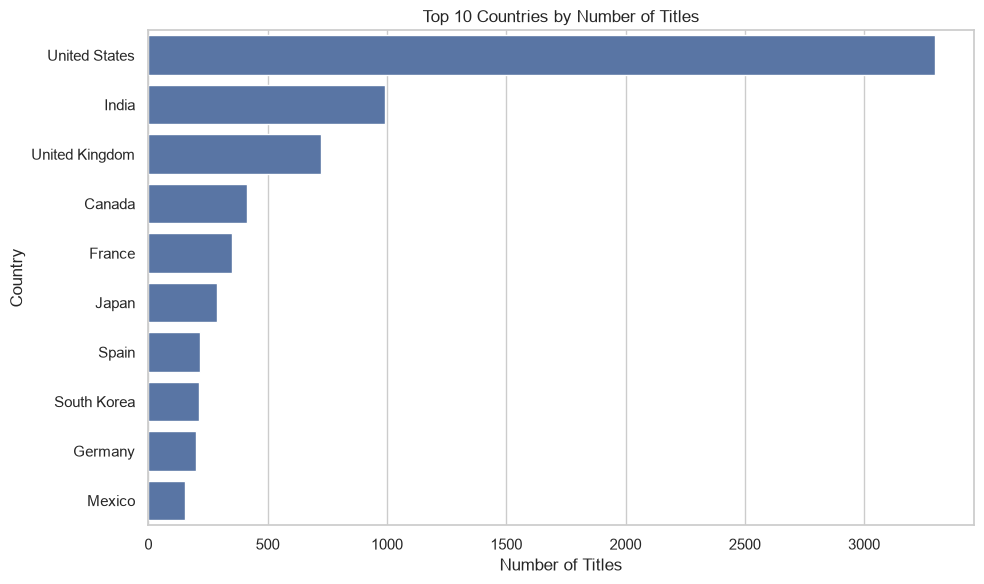

In [10]:
country_counts = (
    df["country"]
    .str.split(", ")
    .explode()
    .str.strip()
)

country_counts = country_counts[
    country_counts != "Unknown"
].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

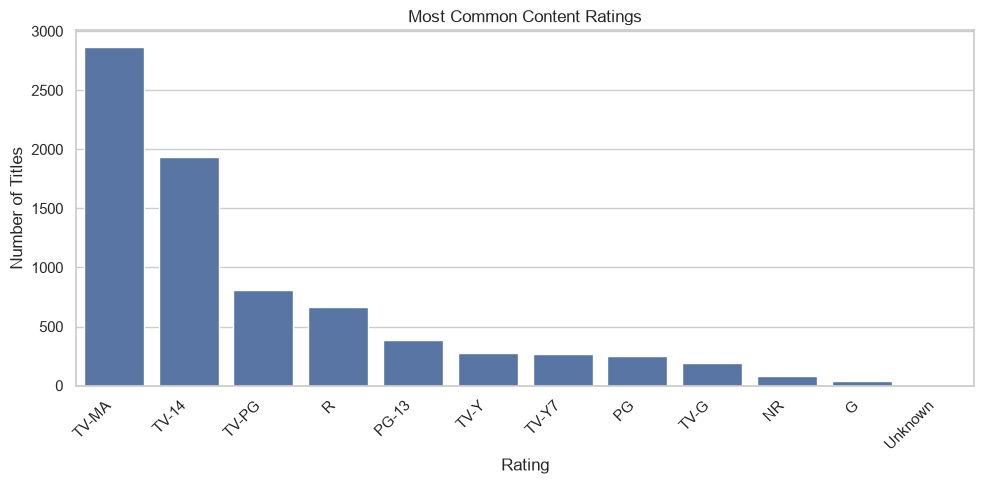

In [11]:
rating_counts = df["rating"].value_counts().head(12)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Most Common Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

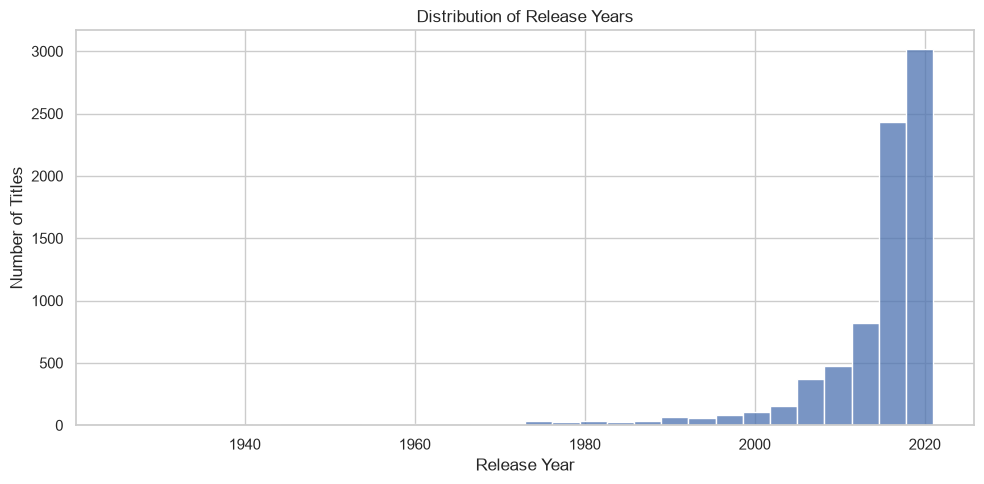

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="release_year",
    bins=30
)

plt.title("Distribution of Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

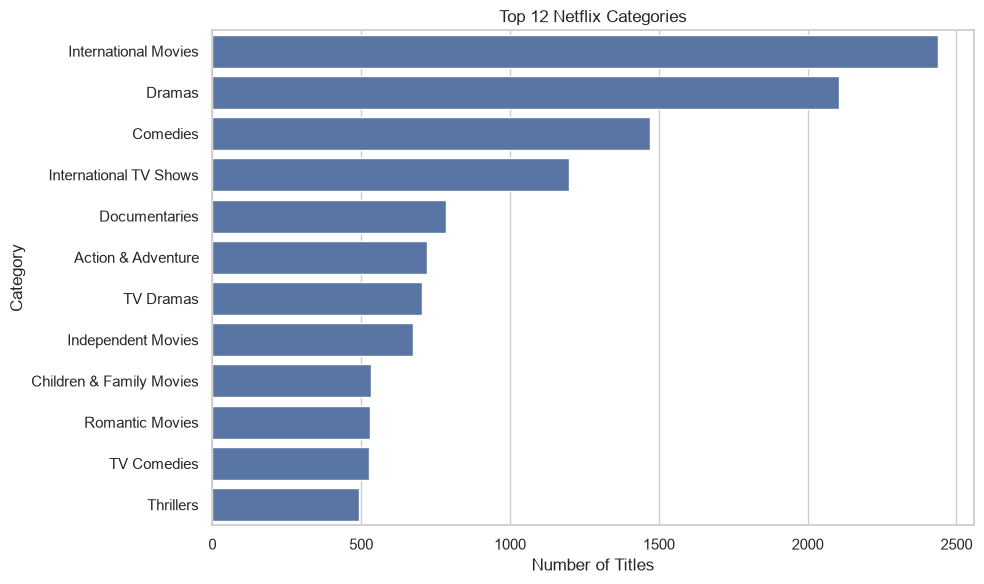

In [13]:
genre_counts = (
    df["listed_in"]
    .str.split(", ")
    .explode()
    .str.strip()
)

genre_counts = genre_counts[
    genre_counts != "Unknown"
].value_counts().head(12)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Top 12 Netflix Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [14]:
df["combined_text"] = (
    df["type"] + " " +
    df["title"] + " " +
    df["listed_in"] + " " +
    df["description"]
).str.lower()

# Year Netflix added the title
df["date_added_year"] = df["date_added"].dt.year

# Description length
df["description_length"] = df["description"].str.len()

print("Feature engineering completed!")

display(
    df[
        [
            "title",
            "type",
            "listed_in",
            "combined_text",
            "date_added_year",
            "description_length"
        ]
    ].head()
)

Feature engineering completed!


,title,type,listed_in,combined_text,date_added_year,description_length
0,3%,TV Show,"International TV Shows, TV Dramas, TV Sci-Fi &...","tv show 3% international tv shows, tv dramas, ...",2020.0,136
1,7:19,Movie,"Dramas, International Movies","movie 7:19 dramas, international movies after ...",2016.0,148
2,23:59,Movie,"Horror Movies, International Movies","movie 23:59 horror movies, international movie...",2018.0,149
3,9,Movie,"Action & Adventure, Independent Movies, Sci-Fi...","movie 9 action & adventure, independent movies...",2017.0,145
4,21,Movie,Dramas,movie 21 dramas a brilliant group of students ...,2020.0,143


In [15]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(df["combined_text"])

print("TF-IDF transformation completed!")
print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF transformation completed!
TF-IDF matrix shape: (7787, 5000)


In [16]:
number_of_components = min(
    100,
    X_tfidf.shape[0] - 1,
    X_tfidf.shape[1] - 1
)

svd = TruncatedSVD(
    n_components=number_of_components,
    random_state=42
)

X_reduced = svd.fit_transform(X_tfidf)

print("Dimensionality reduction completed!")
print("Reduced matrix shape:", X_reduced.shape)

print(
    "Variance captured:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

Dimensionality reduction completed!
Reduced matrix shape: (7787, 100)
Variance captured: 0.2127


In [17]:
# Use a sample for silhouette calculations to reduce processing time
rng = np.random.RandomState(42)

sample_size = min(2000, len(df))

sample_indices = rng.choice(
    len(df),
    size=sample_size,
    replace=False
)

X_sample = X_reduced[sample_indices]

k_values = list(range(2, 9))

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_reduced)

    inertias.append(model.inertia_)

    sample_labels = model.predict(X_sample)

    score = silhouette_score(
        X_sample,
        sample_labels
    )

    silhouette_scores.append(score)

    print(
        f"K={k}, "
        f"Inertia={model.inertia_:.2f}, "
        f"Silhouette Score={score:.4f}"
    )

K=2, Inertia=1429.80, Silhouette Score=0.1432
K=3, Inertia=1379.67, Silhouette Score=0.0930
K=4, Inertia=1337.01, Silhouette Score=0.0610
K=5, Inertia=1298.67, Silhouette Score=0.0813
K=6, Inertia=1257.55, Silhouette Score=0.0939
K=7, Inertia=1230.49, Silhouette Score=0.0942
K=8, Inertia=1201.70, Silhouette Score=0.0796


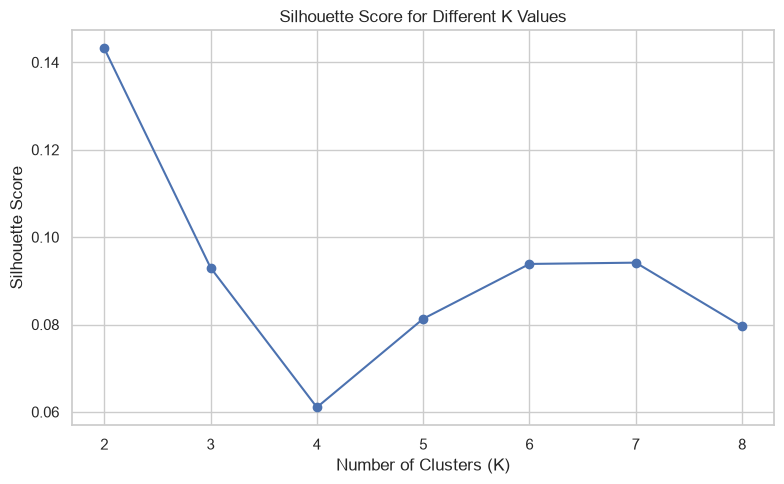

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)

plt.tight_layout()
plt.show()

In [19]:
BEST_K = 5

kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

df["kmeans_cluster"] = kmeans.fit_predict(X_reduced)

print("K-Means clustering completed!")

print("\nNumber of titles in each cluster:")
display(
    df["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

K-Means clustering completed!

Number of titles in each cluster:


kmeans_cluster
0    1227
1     534
2    4194
3     660
4    1172
Name: count, dtype: int64

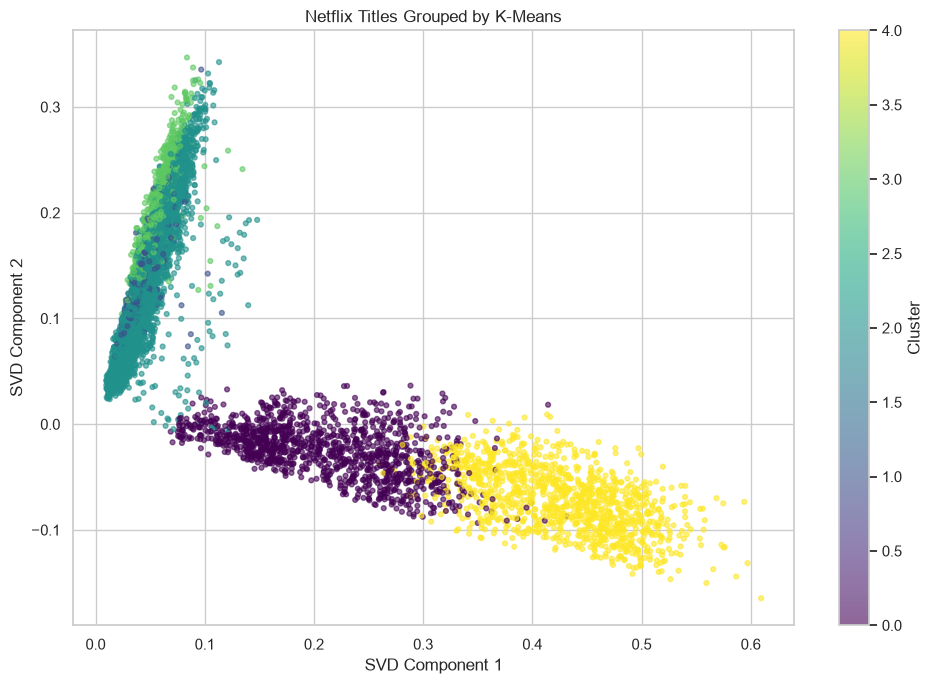

In [20]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=df["kmeans_cluster"],
    cmap="viridis",
    s=12,
    alpha=0.6
)

plt.title("Netflix Titles Grouped by K-Means")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")

plt.colorbar(scatter, label="Cluster")

plt.tight_layout()
plt.show()

In [21]:
hierarchical_sample_size = min(2000, len(df))

hierarchical_indices = rng.choice(
    len(df),
    size=hierarchical_sample_size,
    replace=False
)

X_hierarchical = X_reduced[hierarchical_indices]

hierarchical_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_hierarchical
)

# Initialize all rows as not included in the sample
df["hierarchical_cluster"] = -1

sample_row_indices = df.index[hierarchical_indices]

df.loc[
    sample_row_indices,
    "hierarchical_cluster"
] = hierarchical_labels

print("Hierarchical Clustering completed!")

print("\nCluster sizes in the sample:")
display(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Hierarchical Clustering completed!

Cluster sizes in the sample:


0    1187
1     424
2     168
3      92
4     129
Name: count, dtype: int64

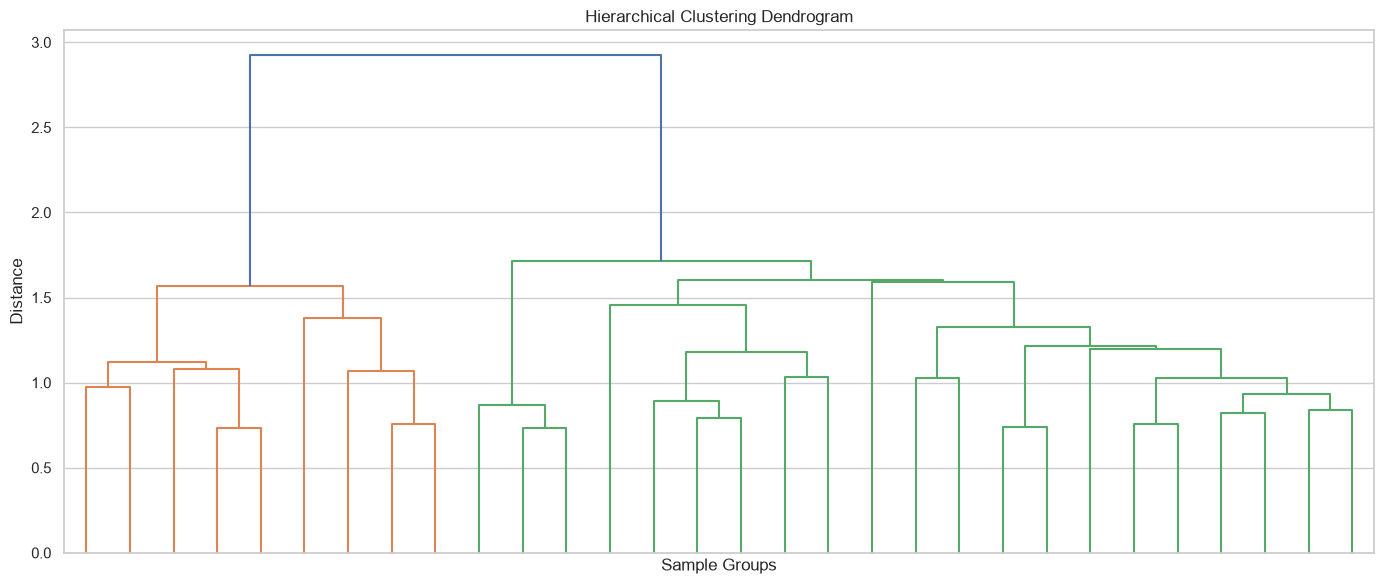

In [22]:
dendrogram_sample_size = min(200, len(df))

dendrogram_indices = rng.choice(
    len(df),
    size=dendrogram_sample_size,
    replace=False
)

X_dendrogram = X_reduced[dendrogram_indices]

linked = linkage(
    X_dendrogram,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linked,
    no_labels=True,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Groups")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

In [23]:
for cluster_number in sorted(df["kmeans_cluster"].unique()):

    cluster_df = df[
        df["kmeans_cluster"] == cluster_number
    ]

    print("\n" + "=" * 50)
    print(f"CLUSTER {cluster_number}")
    print("Number of titles:", len(cluster_df))

    # Find common categories in this cluster
    categories = (
        cluster_df["listed_in"]
        .str.split(", ")
        .explode()
    )

    categories = categories[
        categories != "Unknown"
    ]

    print("\nTop 5 categories:")
    print(categories.value_counts().head(5))

    # Display sample titles
    print("\nExample titles:")
    print(
        cluster_df["title"]
        .head(10)
        .to_string(index=False)
    )


CLUSTER 0
Number of titles: 1227

Top 5 categories:
listed_in
Kids' TV                  413
TV Comedies               290
Docuseries                273
International TV Shows    177
Reality TV                172
Name: count, dtype: int64

Example titles:
​SAINT SEIYA: Knights of the Zodiac
                           (Un)Well
                           #blackAF
                         100 Humans
 13 Reasons Why: Beyond the Reasons
                           21 Again
           3Below: Tales of Arcadia
                            44 Cats
                         60 Days In
                          7 (Seven)

CLUSTER 1
Number of titles: 534

Top 5 categories:
listed_in
Children & Family Movies    532
Comedies                    225
Dramas                       75
Music & Musicals             27
Action & Adventure           21
Name: count, dtype: int64

Example titles:
                    48 Christmas Wishes
                           A 2nd Chance
A Babysitter's Guide to Monster Hunting

In [24]:
comparison_df = pd.DataFrame({
    "Number of Clusters (K)": k_values,
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(comparison_df)

best_position = int(np.argmax(silhouette_scores))

print(
    "K with the highest sample silhouette score:",
    k_values[best_position]
)

print(
    "Highest sample silhouette score:",
    round(silhouette_scores[best_position], 4)
)

,Number of Clusters (K),Inertia,Silhouette Score
0,2,1429.801716,0.143173
1,3,1379.673285,0.092993
2,4,1337.010888,0.061049
3,5,1298.670970,0.081310
4,6,1257.545034,0.093856
5,7,1230.487237,0.094152
6,8,1201.696165,0.079580


K with the highest sample silhouette score: 2
Highest sample silhouette score: 0.1432


In [25]:
print("BUSINESS APPLICATIONS")
print("1. Group similar movies and TV shows.")
print("2. Explore the genres available on Netflix.")
print("3. Support experiments with recommendation systems.")
print("4. Help content teams explore similarities between titles.")
print("5. Discover content themes for further analysis.")

BUSINESS APPLICATIONS
1. Group similar movies and TV shows.
2. Explore the genres available on Netflix.
3. Support experiments with recommendation systems.
4. Help content teams explore similarities between titles.
5. Discover content themes for further analysis.


In [26]:
output_file = "netflix_clustered_results.csv"

df.to_csv(output_file, index=False)

print("Final dataset saved successfully!")
print("Output file:", output_file)
print("Final dataset shape:", df.shape)

display(df.head())

Final dataset saved successfully!
Output file: netflix_clustered_results.csv
Final dataset shape: (7787, 17)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,combined_text,date_added_year,description_length,kmeans_cluster,hierarchical_cluster
0,s1,TV Show,3%,Unknown,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,2020-08-14,2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...,"tv show 3% international tv shows, tv dramas, ...",2020.0,136,4,1
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,2016-12-23,2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,"movie 7:19 dramas, international movies after ...",2016.0,148,2,0
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,2018-12-20,2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...","movie 23:59 horror movies, international movie...",2018.0,149,2,-1
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,2017-11-16,2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...","movie 9 action & adventure, independent movies...",2017.0,145,2,0
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,2020-01-01,2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...,movie 21 dramas a brilliant group of students ...,2020.0,143,2,0


In [27]:
print("""
PROJECT CONCLUSION

In this project, we analyzed the Netflix Movies and TV Shows
dataset using Unsupervised Machine Learning.

First, we performed Exploratory Data Analysis to understand the
dataset. We then cleaned missing text values and removed duplicates.

Next, we created a combined text feature and used TF-IDF to convert
text into numerical features. TruncatedSVD reduced the number of
dimensions to make clustering more manageable.

We applied K-Means and Hierarchical Clustering to group similar
Netflix titles. We also used the Elbow Method and Silhouette Scores
to help evaluate the number of clusters.

Finally, we examined common categories and example titles to
understand the resulting groups.

This project demonstrates how unsupervised machine learning can
help organize and explore similar content. Further validation
would be needed before using these clusters in a real
recommendation system.
""")


PROJECT CONCLUSION

In this project, we analyzed the Netflix Movies and TV Shows
dataset using Unsupervised Machine Learning.

First, we performed Exploratory Data Analysis to understand the
dataset. We then cleaned missing text values and removed duplicates.

Next, we created a combined text feature and used TF-IDF to convert
text into numerical features. TruncatedSVD reduced the number of
dimensions to make clustering more manageable.

We applied K-Means and Hierarchical Clustering to group similar
Netflix titles. We also used the Elbow Method and Silhouette Scores
to help evaluate the number of clusters.

Finally, we examined common categories and example titles to
understand the resulting groups.

This project demonstrates how unsupervised machine learning can
help organize and explore similar content. Further validation
would be needed before using these clusters in a real
recommendation system.

